# Projet Machine Learning : Prédiction de la Survie des Passagers du Titanic

---

### 👤 Travail réalisé par

- **Nom & Prénom** : Bellafrouh Hajar
- **Numéro d’étudiant** : 10
- **Filière** : IID2
- **Année universitaire** : 2025/2026
- **Établissement** : ENSA Khouribga

---


### 👨‍🏫 Encadrant
- **Enseignant** : Pr Ghazdali 

## Table des Matières

1. [Phase 1 — Compréhension du problème](#phase1)
2. [Phase 2 — Compréhension des données](#phase2)
3. [Phase 3 — Analyse exploratoire des données (EDA)](#phase3)
4. [Phase 4 — Nettoyage et préparation des données](#phase4)
5. [Phase 5 — Feature Engineering avancé](#phase5)
6. [Phase 6 — Construction du jeu de données ML](#phase6)
7. [Phase 7 — Modélisation avec Cross-Validation](#phase7)
8. [Phase 8 — Optimisation avec GridSearchCV](#phase8)
9. [Phase 9 — Tableau comparatif détaillé](#phase9)
10. [Phase 10 — Prédictions Kaggle](#phase10)
11. [Phase 11 — Interprétation et analyse critique](#phase11)
12. [Phase 12 — Conclusion et perspectives](#phase12)

## Import des bibliothèques nécessaires

In [4]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Évaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

# Configuration
import warnings
warnings.filterwarnings('ignore')

# Configuration de l'affichage
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
%matplotlib inline

print("✓ Toutes les bibliothèques ont été importées avec succès")

✓ Toutes les bibliothèques ont été importées avec succès


---
<a id='phase1'></a>
## Phase 1 — Compréhension du problème

### Objectif du projet
Prédire si un passager du Titanic a survécu ou non au naufrage en utilisant des algorithmes de Machine Learning.

### Variable cible
- **Survived** : 0 = Décédé, 1 = Survécu

### Type de problème
- **Classification binaire supervisée**

### Question de Machine Learning
Peut-on prédire la probabilité de survie d'un passager en fonction de ses caractéristiques personnelles (âge, sexe, classe, etc.) ?

In [5]:
# Définition des objectifs
print("="*70)
print("PROJET TITANIC - VERSION AMÉLIORÉE")
print("="*70)
print("\n📋 Type de problème : Classification binaire supervisée")
print("🎯 Variable cible : Survived (0 = Décédé, 1 = Survécu)")
print("📊 Question ML : Prédire la survie en fonction des caractéristiques")
print("\n🆕 AMÉLIORATIONS :")
print("  ✅ Feature Engineering (création de nouvelles variables)")
print("  ✅ Cross-Validation (validation croisée 5-fold)")
print("  ✅ GridSearchCV (optimisation automatique)")
print("  ✅ Tableau comparatif détaillé")
print("  ✅ Prédictions Kaggle")
print("="*70)

PROJET TITANIC - VERSION AMÉLIORÉE

📋 Type de problème : Classification binaire supervisée
🎯 Variable cible : Survived (0 = Décédé, 1 = Survécu)
📊 Question ML : Prédire la survie en fonction des caractéristiques

🆕 AMÉLIORATIONS :
  ✅ Feature Engineering (création de nouvelles variables)
  ✅ Cross-Validation (validation croisée 5-fold)
  ✅ GridSearchCV (optimisation automatique)
  ✅ Tableau comparatif détaillé
  ✅ Prédictions Kaggle


---
<a id='phase2'></a>
## Phase 2 — Compréhension des données

### Chargement des datasets

In [6]:
# Chargement des données
df_train = pd.read_csv('../data/train.csv')
df_test = pd.read_csv('../data/test.csv')

print("✓ Datasets chargés avec succès")
print("\n📊 TRAIN.CSV")
print(f"Nombre de lignes : {df_train.shape[0]}")
print(f"Nombre de colonnes : {df_train.shape[1]}")

print("\n📊 TEST.CSV (Kaggle)")
print(f"Nombre de lignes : {df_test.shape[0]}")
print(f"Nombre de colonnes : {df_test.shape[1]}")

✓ Datasets chargés avec succès

📊 TRAIN.CSV
Nombre de lignes : 891
Nombre de colonnes : 12

📊 TEST.CSV (Kaggle)
Nombre de lignes : 418
Nombre de colonnes : 11


### Aperçu des données

In [7]:
print("\n📊 Aperçu du dataset d'entraînement :")
display(df_train.head())

print("\n📊 Informations sur le dataset :")
df_train.info()


📊 Aperçu du dataset d'entraînement :


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



📊 Informations sur le dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


### Description des variables

In [8]:
print("\n📋 DESCRIPTION DES VARIABLES")
print("="*70)
variables = {
    'PassengerId': 'Identifiant unique du passager',
    'Survived': 'Variable cible (0 = Décédé, 1 = Survécu)',
    'Pclass': 'Classe du billet (1 = 1ère, 2 = 2ème, 3 = 3ème)',
    'Name': 'Nom du passager',
    'Sex': 'Sexe (male/female)',
    'Age': 'Âge en années',
    'SibSp': 'Nombre de frères/sœurs/conjoints à bord',
    'Parch': 'Nombre de parents/enfants à bord',
    'Ticket': 'Numéro du billet',
    'Fare': 'Prix du billet',
    'Cabin': 'Numéro de cabine',
    'Embarked': 'Port d\'embarquement (C = Cherbourg, Q = Queenstown, S = Southampton)'
}

for var, desc in variables.items():
    print(f"• {var:12} : {desc}")
print("="*70)


📋 DESCRIPTION DES VARIABLES
• PassengerId  : Identifiant unique du passager
• Survived     : Variable cible (0 = Décédé, 1 = Survécu)
• Pclass       : Classe du billet (1 = 1ère, 2 = 2ème, 3 = 3ème)
• Name         : Nom du passager
• Sex          : Sexe (male/female)
• Age          : Âge en années
• SibSp        : Nombre de frères/sœurs/conjoints à bord
• Parch        : Nombre de parents/enfants à bord
• Ticket       : Numéro du billet
• Fare         : Prix du billet
• Cabin        : Numéro de cabine
• Embarked     : Port d'embarquement (C = Cherbourg, Q = Queenstown, S = Southampton)


---
<a id='phase3'></a>
## Phase 3 — Analyse exploratoire des données (EDA)

In [9]:
# Statistiques descriptives
print("\n📊 STATISTIQUES DESCRIPTIVES")
print("="*70)
display(df_train.describe())


📊 STATISTIQUES DESCRIPTIVES


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
# Valeurs manquantes
print("\n⚠️ VALEURS MANQUANTES")
print("="*70)
missing = df_train.isnull().sum()
missing_pct = (missing / len(df_train)) * 100
missing_df = pd.DataFrame({
    'Nombre manquant': missing,
    'Pourcentage (%)': missing_pct
})
missing_df = missing_df[missing_df['Nombre manquant'] > 0].sort_values('Nombre manquant', ascending=False)
display(missing_df)


⚠️ VALEURS MANQUANTES


,Nombre manquant,Pourcentage (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


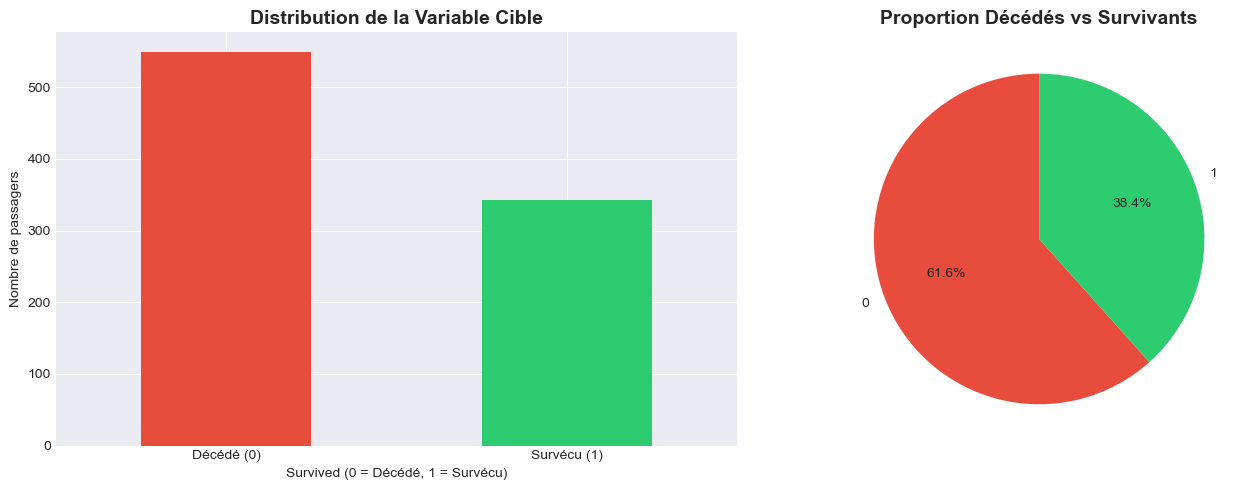


📊 Taux de survie : 38.38%
📊 Taux de décès : 61.62%


In [11]:
# Visualisation de la distribution de la variable cible
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Distribution
df_train['Survived'].value_counts().plot(kind='bar', ax=axes[0], color=['#e74c3c', '#2ecc71'])
axes[0].set_title('Distribution de la Variable Cible', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Survived (0 = Décédé, 1 = Survécu)')
axes[0].set_ylabel('Nombre de passagers')
axes[0].set_xticklabels(['Décédé (0)', 'Survécu (1)'], rotation=0)

# Graphique 2 : Pourcentage
survived_pct = df_train['Survived'].value_counts(normalize=True) * 100
survived_pct.plot(kind='pie', ax=axes[1], autopct='%1.1f%%', colors=['#e74c3c', '#2ecc71'], startangle=90)
axes[1].set_title('Proportion Décédés vs Survivants', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print(f"\n📊 Taux de survie : {survived_pct[1]:.2f}%")
print(f"📊 Taux de décès : {survived_pct[0]:.2f}%")

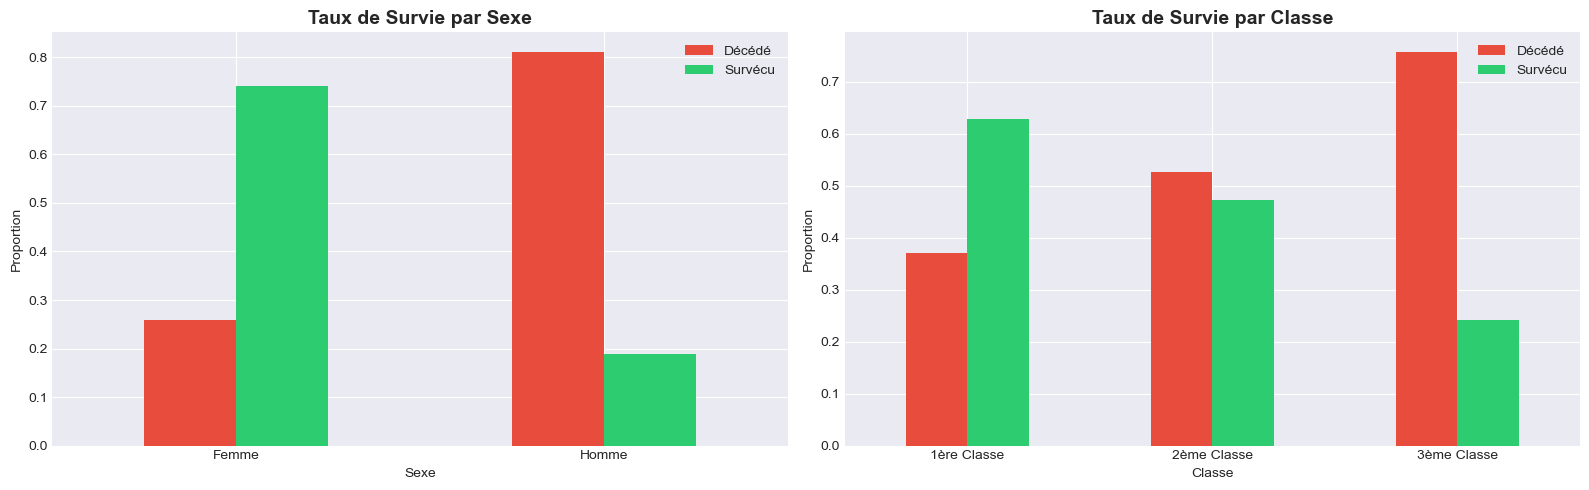

In [12]:
# Analyse de survie par sexe et classe
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Par sexe
pd.crosstab(df_train['Sex'], df_train['Survived'], normalize='index').plot(
    kind='bar', ax=axes[0], color=['#e74c3c', '#2ecc71']
)
axes[0].set_title('Taux de Survie par Sexe', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sexe')
axes[0].set_ylabel('Proportion')
axes[0].legend(['Décédé', 'Survécu'])
axes[0].set_xticklabels(['Femme', 'Homme'], rotation=0)

# Par classe
pd.crosstab(df_train['Pclass'], df_train['Survived'], normalize='index').plot(
    kind='bar', ax=axes[1], color=['#e74c3c', '#2ecc71']
)
axes[1].set_title('Taux de Survie par Classe', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Classe')
axes[1].set_ylabel('Proportion')
axes[1].legend(['Décédé', 'Survécu'])
axes[1].set_xticklabels(['1ère Classe', '2ème Classe', '3ème Classe'], rotation=0)

plt.tight_layout()
plt.show()

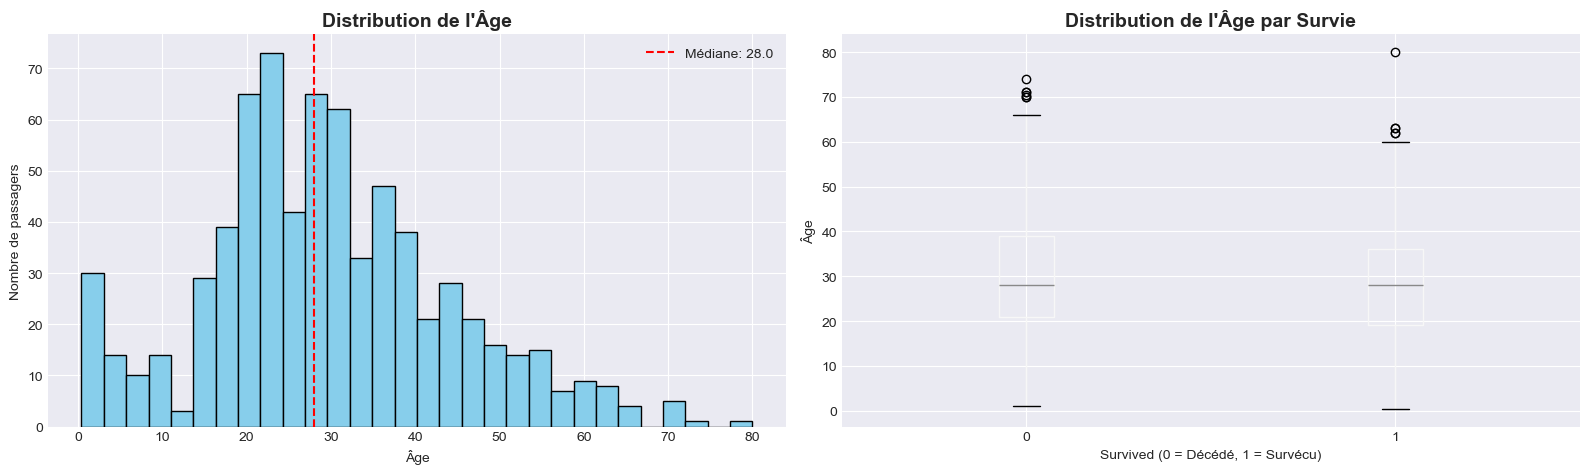

In [13]:
# Distribution de l'âge
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histogramme de l'âge
df_train['Age'].hist(bins=30, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Distribution de l\'Âge', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Âge')
axes[0].set_ylabel('Nombre de passagers')
axes[0].axvline(df_train['Age'].median(), color='red', linestyle='--', label=f'Médiane: {df_train["Age"].median():.1f}')
axes[0].legend()

# Boxplot de l'âge par survie
df_train.boxplot(column='Age', by='Survived', ax=axes[1])
axes[1].set_title('Distribution de l\'Âge par Survie', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Survived (0 = Décédé, 1 = Survécu)')
axes[1].set_ylabel('Âge')

plt.suptitle('')
plt.tight_layout()
plt.show()

---
<a id='phase4'></a>
## Phase 4 — Nettoyage et préparation des données

In [14]:
# Fonction de nettoyage pour appliquer sur train et test
def clean_data(df):
    """
    Nettoie le dataset en gérant les valeurs manquantes
    """
    df = df.copy()
    
    # 1. Imputation de l'âge par la médiane
    df['Age'].fillna(df['Age'].median(), inplace=True)
    
    # 2. Imputation du port d'embarquement par le mode
    df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)
    
    # 3. Imputation du prix par la médiane
    df['Fare'].fillna(df['Fare'].median(), inplace=True)
    
    # 4. Suppression de la cabine (trop de valeurs manquantes)
    df.drop('Cabin', axis=1, inplace=True)
    
    return df

# Application du nettoyage
df_train_clean = clean_data(df_train)
df_test_clean = clean_data(df_test)

print("✓ Nettoyage des données effectué")
print("\n⚠️ Vérification des valeurs manquantes après nettoyage :")
print("\nTRAIN:")
print(df_train_clean.isnull().sum())
print("\nTEST:")
print(df_test_clean.isnull().sum())

✓ Nettoyage des données effectué

⚠️ Vérification des valeurs manquantes après nettoyage :

TRAIN:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

TEST:
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


---
<a id='phase5'></a>
## Phase 5 — Feature Engineering Avancé

### Création de nouvelles variables pour améliorer le modèle

**Nouvelles features créées :**
1. **Title** : Extraction du titre depuis le nom (Mr, Mrs, Miss, Master, etc.)
2. **FamilySize** : Taille totale de la famille (SibSp + Parch + 1)
3. **IsAlone** : Voyageur seul (1) ou accompagné (0)
4. **Age_Group** : Catégorisation de l'âge (Enfant, Jeune, Adulte, Senior)
5. **Fare_Category** : Catégorisation du prix du billet

In [15]:
def feature_engineering(df):
    """
    Crée de nouvelles variables à partir des variables existantes
    """
    df = df.copy()
    
    # 1. Extraction du titre depuis le nom
    df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
    
    # Regroupement des titres rares
    df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col','Don', 'Dr', 'Major', 
                                        'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
    df['Title'] = df['Title'].replace('Mlle', 'Miss')
    df['Title'] = df['Title'].replace('Ms', 'Miss')
    df['Title'] = df['Title'].replace('Mme', 'Mrs')
    
    # 2. Taille de la famille
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    
    # 3. Voyageur seul ou pas
    df['IsAlone'] = 1  # Par défaut, seul
    df['IsAlone'].loc[df['FamilySize'] > 1] = 0  # Pas seul si famille > 1
    
    # 4. Catégories d'âge
    df['Age_Group'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 100], 
                              labels=['Enfant', 'Adolescent', 'Jeune_Adulte', 'Adulte', 'Senior'])
    
    # 5. Catégories de prix
    df['Fare_Category'] = pd.qcut(df['Fare'], q=4, labels=['Bas', 'Moyen', 'Élevé', 'Très_Élevé'], 
                                   duplicates='drop')
    
    return df

# Application du feature engineering
df_train_fe = feature_engineering(df_train_clean)
df_test_fe = feature_engineering(df_test_clean)

print("✓ Feature Engineering effectué")
print("\n🆕 NOUVELLES VARIABLES CRÉÉES :")
print("="*70)
print("1. Title        : Titre extrait du nom (Mr, Mrs, Miss, Master, Rare)")
print("2. FamilySize   : Taille de la famille (SibSp + Parch + 1)")
print("3. IsAlone      : 1 si seul, 0 si accompagné")
print("4. Age_Group    : Catégorie d'âge (Enfant, Adolescent, etc.)")
print("5. Fare_Category: Catégorie de prix (Bas, Moyen, Élevé, Très_Élevé)")
print("="*70)

✓ Feature Engineering effectué

🆕 NOUVELLES VARIABLES CRÉÉES :
1. Title        : Titre extrait du nom (Mr, Mrs, Miss, Master, Rare)
2. FamilySize   : Taille de la famille (SibSp + Parch + 1)
3. IsAlone      : 1 si seul, 0 si accompagné
4. Age_Group    : Catégorie d'âge (Enfant, Adolescent, etc.)
5. Fare_Category: Catégorie de prix (Bas, Moyen, Élevé, Très_Élevé)


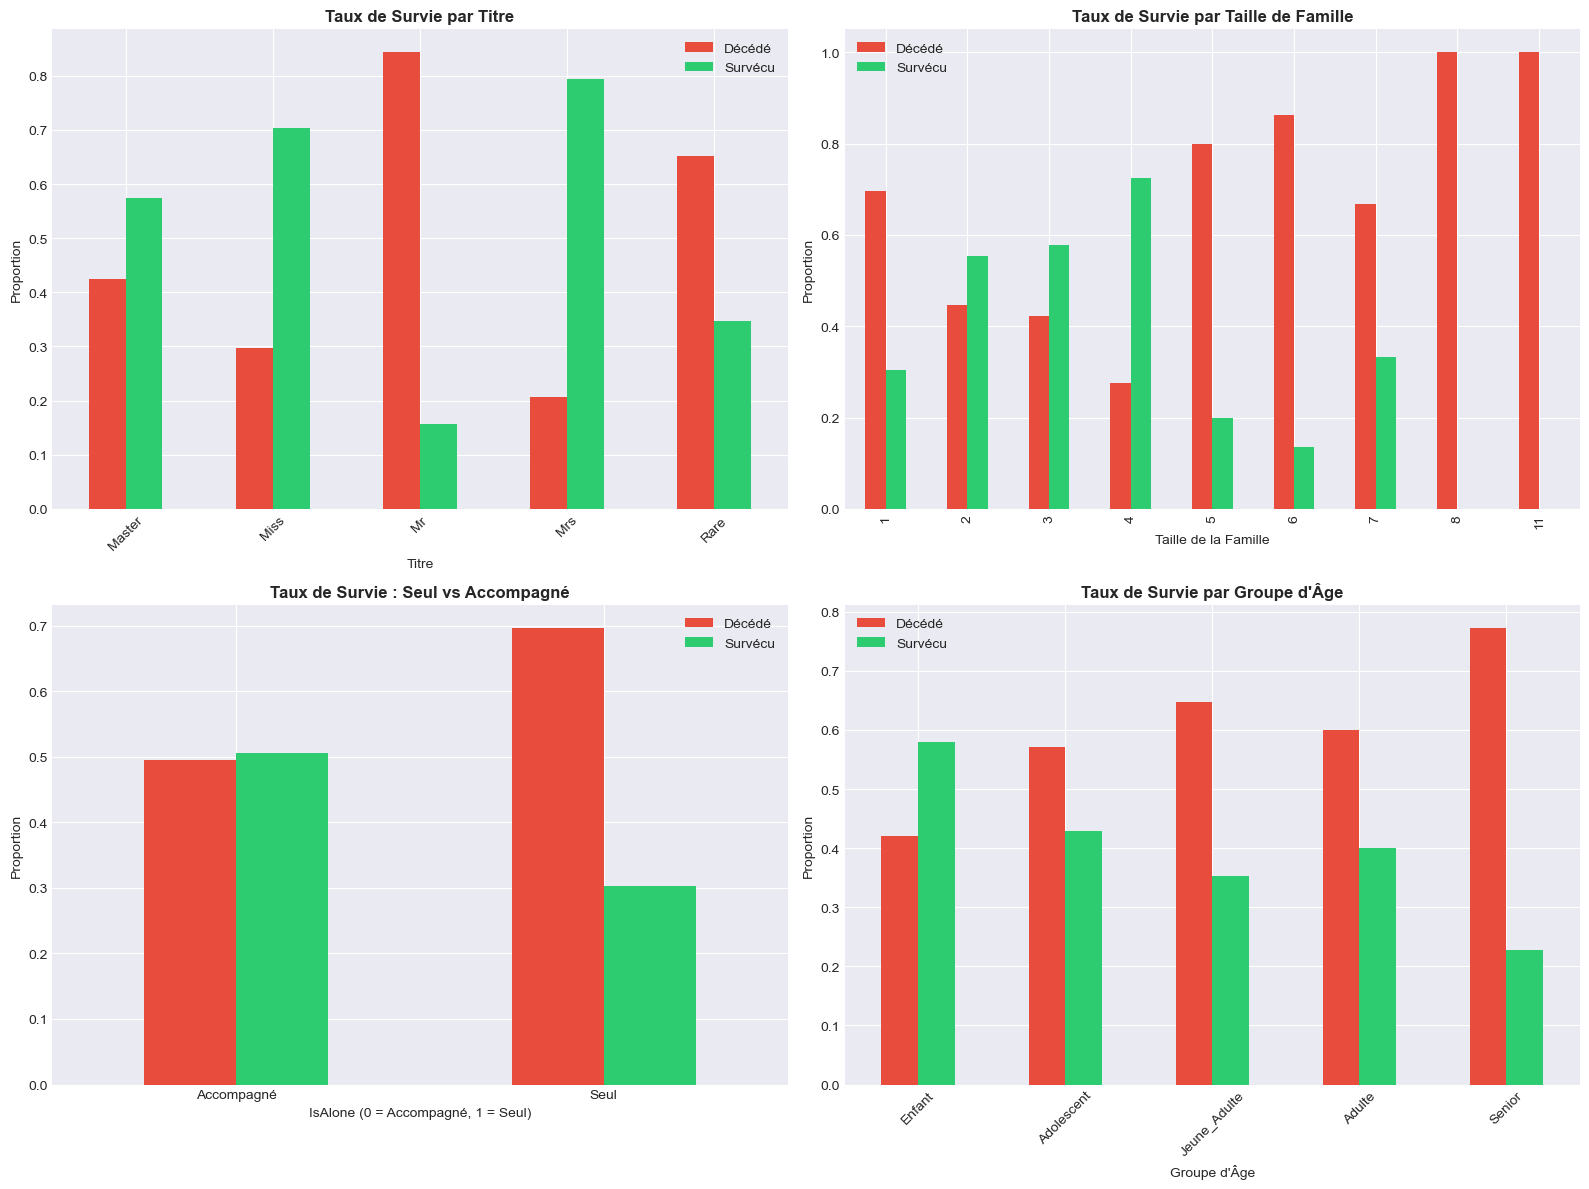


✅ Les nouvelles variables montrent des patterns intéressants pour la prédiction !


In [16]:
# Visualisation de l'impact des nouvelles features
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Survie par titre
pd.crosstab(df_train_fe['Title'], df_train_fe['Survived'], normalize='index').plot(
    kind='bar', ax=axes[0, 0], color=['#e74c3c', '#2ecc71']
)
axes[0, 0].set_title('Taux de Survie par Titre', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Titre')
axes[0, 0].set_ylabel('Proportion')
axes[0, 0].legend(['Décédé', 'Survécu'])
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Survie par taille de famille
pd.crosstab(df_train_fe['FamilySize'], df_train_fe['Survived'], normalize='index').plot(
    kind='bar', ax=axes[0, 1], color=['#e74c3c', '#2ecc71']
)
axes[0, 1].set_title('Taux de Survie par Taille de Famille', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Taille de la Famille')
axes[0, 1].set_ylabel('Proportion')
axes[0, 1].legend(['Décédé', 'Survécu'])

# 3. Survie : seul vs accompagné
pd.crosstab(df_train_fe['IsAlone'], df_train_fe['Survived'], normalize='index').plot(
    kind='bar', ax=axes[1, 0], color=['#e74c3c', '#2ecc71']
)
axes[1, 0].set_title('Taux de Survie : Seul vs Accompagné', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('IsAlone (0 = Accompagné, 1 = Seul)')
axes[1, 0].set_ylabel('Proportion')
axes[1, 0].legend(['Décédé', 'Survécu'])
axes[1, 0].set_xticklabels(['Accompagné', 'Seul'], rotation=0)

# 4. Survie par groupe d'âge
pd.crosstab(df_train_fe['Age_Group'], df_train_fe['Survived'], normalize='index').plot(
    kind='bar', ax=axes[1, 1], color=['#e74c3c', '#2ecc71']
)
axes[1, 1].set_title('Taux de Survie par Groupe d\'Âge', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Groupe d\'Âge')
axes[1, 1].set_ylabel('Proportion')
axes[1, 1].legend(['Décédé', 'Survécu'])
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n✅ Les nouvelles variables montrent des patterns intéressants pour la prédiction !")

---
<a id='phase6'></a>
## Phase 6 — Construction du jeu de données ML

In [17]:
# Sélection et encodage des features
def prepare_features(df, is_train=True):
    """
    Prépare les features pour le ML en encodant les variables catégorielles
    """
    df = df.copy()
    
    # Variables à garder
    features_to_keep = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked',
                        'Title', 'FamilySize', 'IsAlone', 'Age_Group', 'Fare_Category']
    
    # Sélection des features
    if is_train:
        df_features = df[features_to_keep + ['Survived']].copy()
    else:
        df_features = df[features_to_keep].copy()
    
    # Encodage des variables catégorielles
    categorical_cols = ['Sex', 'Embarked', 'Title', 'Age_Group', 'Fare_Category']
    
    for col in categorical_cols:
        le = LabelEncoder()
        df_features[col] = le.fit_transform(df_features[col].astype(str))
    
    return df_features

# Préparation des datasets
df_train_prepared = prepare_features(df_train_fe, is_train=True)
df_test_prepared = prepare_features(df_test_fe, is_train=False)

print("✓ Features préparées et encodées")
print("\n📊 APERÇU DES FEATURES :")
display(df_train_prepared.head())

✓ Features préparées et encodées

📊 APERÇU DES FEATURES :


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,Age_Group,Fare_Category,Survived
0,3,1,22.0,1,0,7.2500,2,2,2,0,3,0,0
1,1,0,38.0,1,0,71.2833,0,3,2,0,1,2,1
2,3,0,26.0,0,0,7.9250,2,1,1,1,3,1,1
3,1,0,35.0,1,0,53.1000,2,3,2,0,3,2,1
4,3,1,35.0,0,0,8.0500,2,2,1,1,3,1,0


In [18]:
# Séparation features et target
X = df_train_prepared.drop('Survived', axis=1)
y = df_train_prepared['Survived']

# Division train/test pour validation locale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("✓ Division des données effectuée (80% train / 20% test)")
print("\n📊 TAILLE DES SOUS-ENSEMBLES")
print("="*70)
print(f"Jeu d'entraînement (X_train) : {X_train.shape}")
print(f"Jeu de test (X_test) : {X_test.shape}")
print(f"\nCible d'entraînement (y_train) : {y_train.shape}")
print(f"Cible de test (y_test) : {y_test.shape}")
print("="*70)

# Distribution
print("\n📈 Distribution de la cible :")
print(f"Train : {y_train.value_counts().to_dict()}")
print(f"Test : {y_test.value_counts().to_dict()}")

✓ Division des données effectuée (80% train / 20% test)

📊 TAILLE DES SOUS-ENSEMBLES
Jeu d'entraînement (X_train) : (712, 12)
Jeu de test (X_test) : (179, 12)

Cible d'entraînement (y_train) : (712,)
Cible de test (y_test) : (179,)

📈 Distribution de la cible :
Train : {0: 439, 1: 273}
Test : {0: 110, 1: 69}


---
<a id='phase7'></a>
## Phase 7 — Modélisation avec Cross-Validation

###  Qu'est-ce que la Cross-Validation ?

Au lieu de diviser les données une seule fois, la **validation croisée** divise les données en **5 parties** (folds) et teste le modèle 5 fois :

```
Tour 1: [Test] [Train] [Train] [Train] [Train]
Tour 2: [Train] [Test] [Train] [Train] [Train]
Tour 3: [Train] [Train] [Test] [Train] [Train]
Tour 4: [Train] [Train] [Train] [Test] [Train]
Tour 5: [Train] [Train] [Train] [Train] [Test]
```

**Avantage** : On obtient une moyenne des 5 résultats, ce qui est **plus fiable** qu'un seul test !


🔄 ENTRAÎNEMENT DES MODÈLES AVEC CROSS-VALIDATION (5-Fold)

🤖 Entraînement de Logistic Regression...
  ✓ CV Accuracy: 0.8062 (+/- 0.0217)
  ✓ Test Accuracy: 0.8101
  ✓ Test AUC: 0.8597

🤖 Entraînement de Decision Tree...
  ✓ CV Accuracy: 0.7810 (+/- 0.0240)
  ✓ Test Accuracy: 0.8212
  ✓ Test AUC: 0.8015

🤖 Entraînement de Random Forest...
  ✓ CV Accuracy: 0.8188 (+/- 0.0119)
  ✓ Test Accuracy: 0.8380
  ✓ Test AUC: 0.8195

🤖 Entraînement de SVM...
  ✓ CV Accuracy: 0.6868 (+/- 0.0165)
  ✓ Test Accuracy: 0.6257
  ✓ Test AUC: 0.6839

🤖 Entraînement de KNN...
  ✓ CV Accuracy: 0.7177 (+/- 0.0275)
  ✓ Test Accuracy: 0.6592
  ✓ Test AUC: 0.7159

🤖 Entraînement de Gradient Boosting...
  ✓ CV Accuracy: 0.8146 (+/- 0.0226)
  ✓ Test Accuracy: 0.7989
  ✓ Test AUC: 0.8273

✓ Tous les modèles ont été entraînés avec succès !


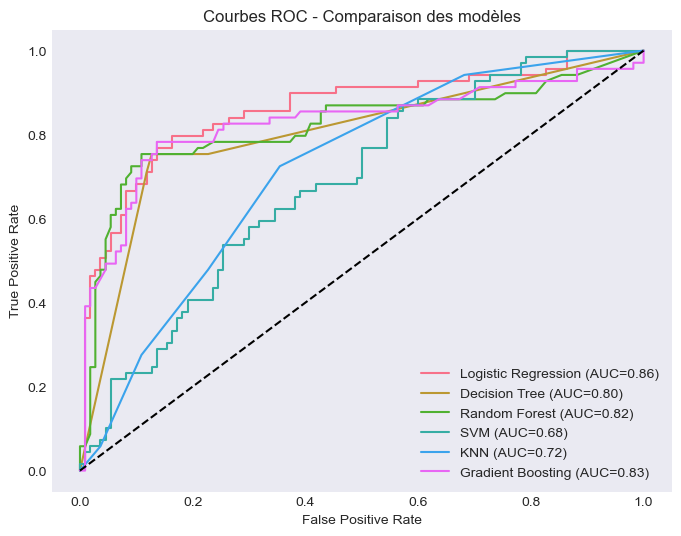

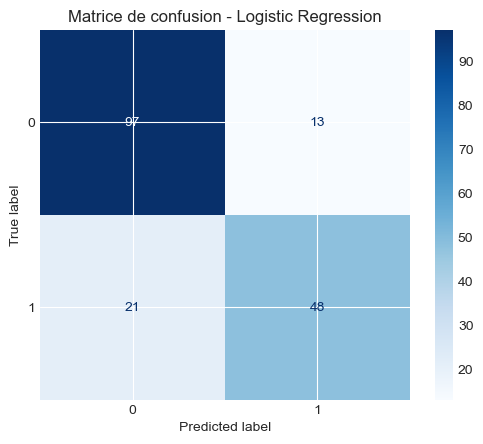

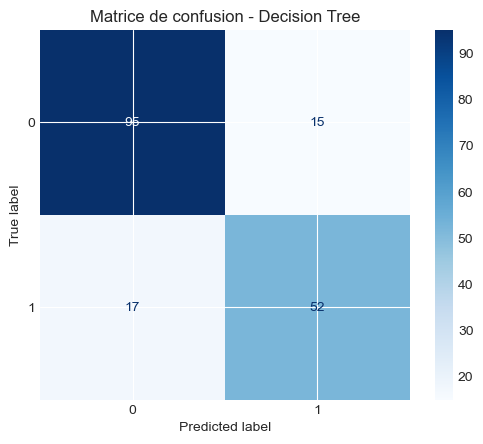

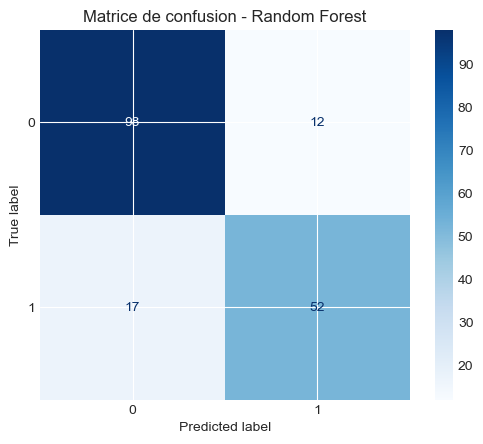

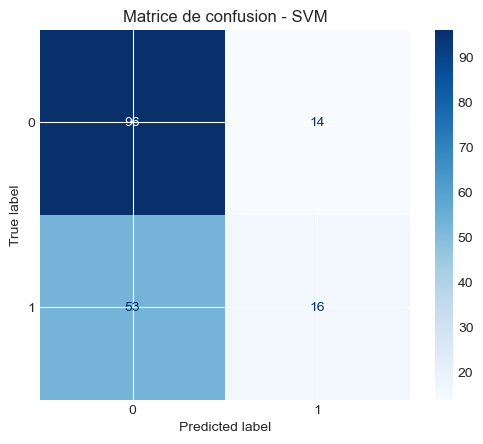

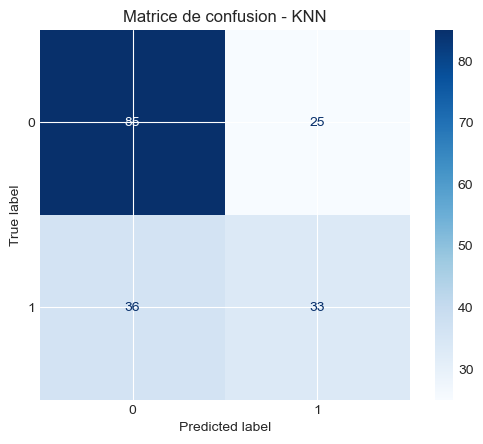

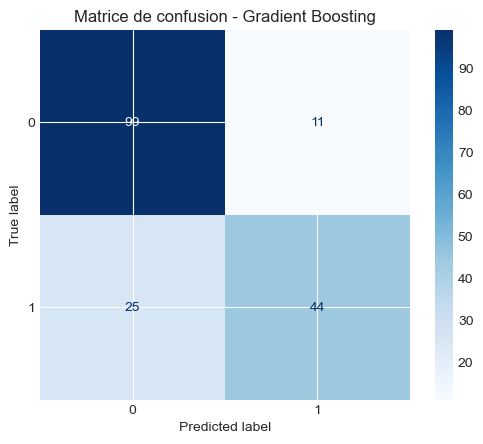

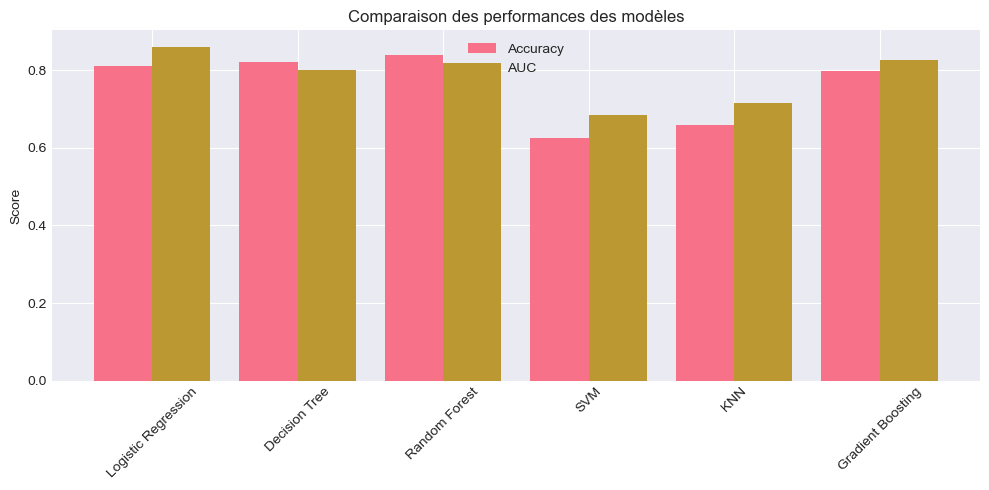

In [19]:
# ===============================
# IMPORTATIONS
# ===============================
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

# ===============================
# DÉFINITION DES MODÈLES
# ===============================
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# ===============================
# CROSS-VALIDATION STRATIFIÉE
# ===============================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results_cv = {}
results_test = {}

print("\n🔄 ENTRAÎNEMENT DES MODÈLES AVEC CROSS-VALIDATION (5-Fold)")
print("=" * 70)

# ===============================
# ENTRAÎNEMENT & ÉVALUATION
# ===============================
for name, model in models.items():
    print(f"\n🤖 Entraînement de {name}...")

    # ----- Cross-validation -----
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    results_cv[name] = {
        'mean': cv_scores.mean(),
        'std': cv_scores.std()
    }

    # ----- Entraînement final -----
    model.fit(X_train, y_train)

    # ----- Prédictions -----
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_pred_proba = model.predict_proba(X_test)[:, 1]
        test_auc = roc_auc_score(y_test, y_pred_proba)
    else:
        y_pred_proba = None
        test_auc = None

    test_accuracy = accuracy_score(y_test, y_pred)

    results_test[name] = {
        'accuracy': test_accuracy,
        'auc': test_auc,
        'y_pred': y_pred,
        'y_proba': y_pred_proba,
        'model': model
    }

    print(f"  ✓ CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
    print(f"  ✓ Test Accuracy: {test_accuracy:.4f}")
    if test_auc is not None:
        print(f"  ✓ Test AUC: {test_auc:.4f}")

print("\n" + "=" * 70)
print("✓ Tous les modèles ont été entraînés avec succès !")

# ======================================================
# 1️⃣ COURBES ROC (COMPARAISON DES MODÈLES)
# ======================================================
plt.figure(figsize=(8, 6))

for name, res in results_test.items():
    if res['y_proba'] is not None:
        fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
        plt.plot(fpr, tpr, label=f"{name} (AUC={res['auc']:.2f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbes ROC - Comparaison des modèles")
plt.legend()
plt.grid()
plt.show()

# ======================================================
# 2️⃣ MATRICES DE CONFUSION (UNE PAR MODÈLE)
# ======================================================
for name, res in results_test.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        res['y_pred'],
        cmap='Blues'
    )
    plt.title(f"Matrice de confusion - {name}")
    plt.show()

# ======================================================
# 3️⃣ COMPARAISON ACCURACY / AUC (BAR CHART)
# ======================================================
model_names = list(results_test.keys())
accuracy_scores = [results_test[m]['accuracy'] for m in model_names]
auc_scores = [
    results_test[m]['auc'] if results_test[m]['auc'] is not None else 0
    for m in model_names
]

x = np.arange(len(model_names))

plt.figure(figsize=(10, 5))
plt.bar(x, accuracy_scores, width=0.4, label='Accuracy')
plt.bar(x + 0.4, auc_scores, width=0.4, label='AUC')
plt.xticks(x + 0.2, model_names, rotation=45)
plt.ylabel("Score")
plt.title("Comparaison des performances des modèles")
plt.legend()
plt.tight_layout()
plt.show()


## l’interprétation des résultats

Plusieurs modèles de classification ont été comparés à l’aide d’une validation croisée à 5 plis et d’un jeu de test indépendant. Les performances ont été évaluées à l’aide des métriques Accuracy et AUC afin d’estimer la capacité de généralisation des modèles.

Le **Random Forest** obtient la meilleure accuracy sur le jeu de test et présente une très bonne stabilité, ce qui en fait le modèle le plus performant globalement.  
La **régression logistique** se distingue par une AUC élevée, indiquant une excellente capacité de discrimination entre les classes, tout en restant simple et interprétable.  
Le **Gradient Boosting** montre également de bonnes performances et constitue une alternative robuste proche du Random Forest.

En revanche, les modèles **SVM** et **KNN** présentent des performances inférieures dans cette configuration, probablement en raison de l’absence de normalisation des données et du manque d’optimisation des hyperparamètres.

### Classement des modèles

#### Selon l’Accuracy sur le jeu de test
1. Random Forest (0.838)  
2. Decision Tree (0.821)  
3. Logistic Regression (0.810)  

#### Selon l’AUC
1. Logistic Regression (0.860)  
2. Gradient Boosting (0.827)  
3. Random Forest (0.820)  



---
<a id='phase8'></a>
## Phase 8 —  Optimisation avec GridSearchCV

### Qu'est-ce que GridSearchCV ?

**GridSearchCV** teste automatiquement différentes combinaisons de paramètres pour trouver la **meilleure configuration** du modèle.

**Exemple** : Pour Random Forest, on teste :
- Nombre d'arbres : 50, 100, 200
- Profondeur : 5, 10, 20, None
- → GridSearchCV teste toutes les combinaisons et trouve la meilleure !

In [20]:
# Sélection du meilleur modèle basé sur la CV
best_model_name_cv = max(results_cv, key=lambda x: results_cv[x]['mean'])
print(f"\n🏆 Meilleur modèle (basé sur CV) : {best_model_name_cv}")
print(f"   Accuracy CV : {results_cv[best_model_name_cv]['mean']:.4f}")

# Optimisation du Random Forest avec GridSearchCV
print("\n🔍 OPTIMISATION DU RANDOM FOREST AVEC GRIDSEARCHCV")
print("="*70)
print("⏳ Recherche des meilleurs hyperparamètres en cours...\n")

# Grille de paramètres à tester
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# GridSearchCV
rf_model = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Entraînement
grid_search.fit(X_train, y_train)

# Meilleurs paramètres
print("\n" + "="*70)
print("✓ Optimisation terminée !")
print("\n🎯 MEILLEURS PARAMÈTRES TROUVÉS :")
print("="*70)
for param, value in grid_search.best_params_.items():
    print(f"  • {param}: {value}")

print(f"\n🏆 Meilleur score CV : {grid_search.best_score_:.4f}")

# Test sur le test set
best_rf = grid_search.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)
accuracy_best_rf = accuracy_score(y_test, y_pred_best_rf)

print(f"🎯 Accuracy sur test set : {accuracy_best_rf:.4f}")
print("="*70)

# Ajout du modèle optimisé aux résultats
results_test['Random Forest (Optimisé)'] = {
    'accuracy': accuracy_best_rf,
    'auc': roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]),
    'y_pred': y_pred_best_rf,
    'model': best_rf
}


🏆 Meilleur modèle (basé sur CV) : Random Forest
   Accuracy CV : 0.8188

🔍 OPTIMISATION DU RANDOM FOREST AVEC GRIDSEARCHCV
⏳ Recherche des meilleurs hyperparamètres en cours...

Fitting 5 folds for each of 108 candidates, totalling 540 fits

✓ Optimisation terminée !

🎯 MEILLEURS PARAMÈTRES TROUVÉS :
  • max_depth: 10
  • min_samples_leaf: 2
  • min_samples_split: 10
  • n_estimators: 50

🏆 Meilleur score CV : 0.8245
🎯 Accuracy sur test set : 0.8045


---
<a id='phase9'></a>
## Phase 9 — Tableau Comparatif Détaillé des Modèles

In [21]:
# Création du tableau comparatif
comparison_data = []

for name in models.keys():
    row = {
        'Modèle': name,
        'CV Mean': f"{results_cv[name]['mean']:.4f}",
        'CV Std': f"{results_cv[name]['std']:.4f}",
        'Test Accuracy': f"{results_test[name]['accuracy']:.4f}",
        'Test AUC': f"{results_test[name]['auc']:.4f}" if results_test[name]['auc'] else 'N/A'
    }
    comparison_data.append(row)

# Ajout du Random Forest optimisé
comparison_data.append({
    'Modèle': 'Random Forest (Optimisé)',
    'CV Mean': f"{grid_search.best_score_:.4f}",
    'CV Std': 'N/A',
    'Test Accuracy': f"{accuracy_best_rf:.4f}",
    'Test AUC': f"{results_test['Random Forest (Optimisé)']['auc']:.4f}"
})

# Création du DataFrame
comparison_df = pd.DataFrame(comparison_data)

print("\n📊 TABLEAU COMPARATIF COMPLET DES MODÈLES")
print("="*90)
display(comparison_df)
print("="*90)

# Identification du meilleur modèle
best_model_overall = max(results_test, key=lambda x: results_test[x]['accuracy'])
print(f"\n🏆 MEILLEUR MODÈLE : {best_model_overall}")
print(f"   Test Accuracy : {results_test[best_model_overall]['accuracy']:.4f}")
print(f"   Test AUC : {results_test[best_model_overall]['auc']:.4f}")


📊 TABLEAU COMPARATIF COMPLET DES MODÈLES


,Modèle,CV Mean,CV Std,Test Accuracy,Test AUC
0,Logistic Regression,0.8062,0.0217,0.8101,0.8597
1,Decision Tree,0.7810,0.0240,0.8212,0.8015
2,Random Forest,0.8188,0.0119,0.8380,0.8195
3,SVM,0.6868,0.0165,0.6257,0.6839
4,KNN,0.7177,0.0275,0.6592,0.7159
5,Gradient Boosting,0.8146,0.0226,0.7989,0.8273
6,Random Forest (Optimisé),0.8245,N/A,0.8045,0.8323



🏆 MEILLEUR MODÈLE : Random Forest
   Test Accuracy : 0.8380
   Test AUC : 0.8195


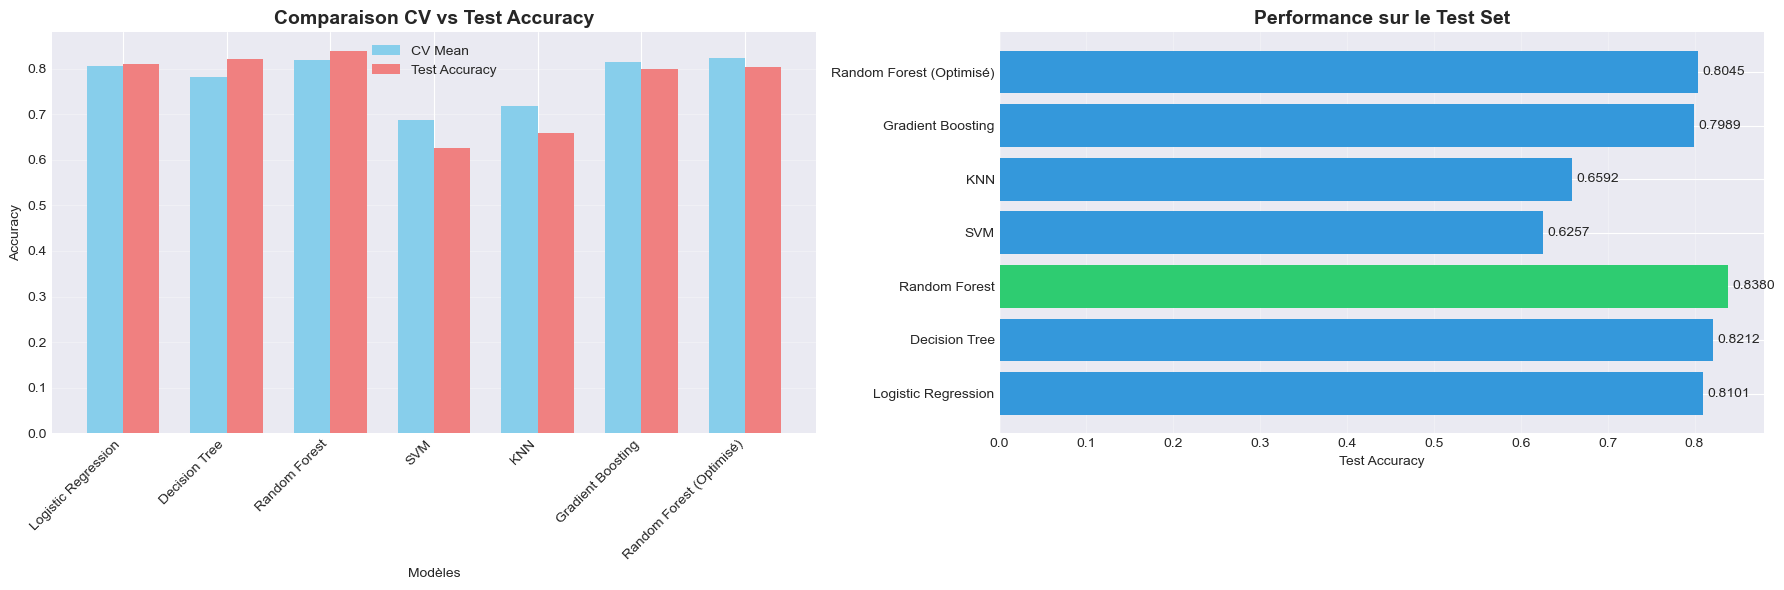

In [22]:
# Visualisation comparative
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Graphique 1 : Comparaison des Accuracy
model_names = [row['Modèle'] for row in comparison_data]
cv_means = [float(row['CV Mean']) for row in comparison_data]
test_accs = [float(row['Test Accuracy']) for row in comparison_data]

x = np.arange(len(model_names))
width = 0.35

axes[0].bar(x - width/2, cv_means, width, label='CV Mean', color='skyblue')
axes[0].bar(x + width/2, test_accs, width, label='Test Accuracy', color='lightcoral')
axes[0].set_xlabel('Modèles')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Comparaison CV vs Test Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Graphique 2 : Test Accuracy seul
colors = ['#2ecc71' if name == best_model_overall else '#3498db' for name in model_names]
axes[1].barh(model_names, test_accs, color=colors)
axes[1].set_xlabel('Test Accuracy')
axes[1].set_title('Performance sur le Test Set', fontsize=14, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

# Ajouter les valeurs sur les barres
for i, v in enumerate(test_accs):
    axes[1].text(v + 0.005, i, f'{v:.4f}', va='center')

plt.tight_layout()
plt.show()


📊 MATRICE DE CONFUSION - Random Forest


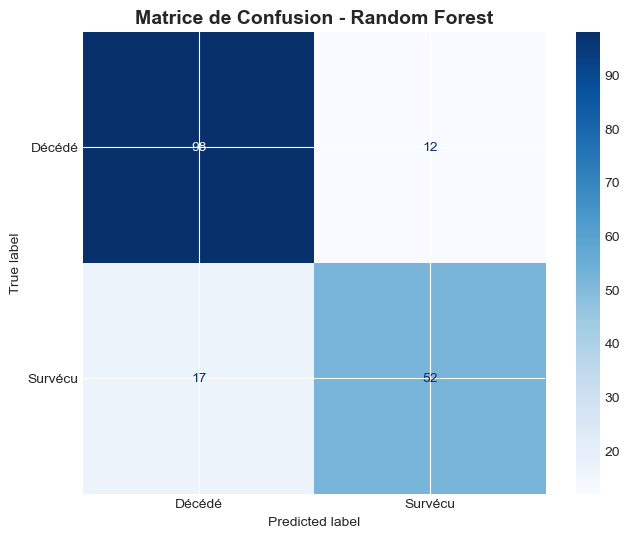


📈 CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Décédé       0.85      0.89      0.87       110
     Survécu       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



In [23]:
# Matrice de confusion du meilleur modèle
from sklearn.metrics import ConfusionMatrixDisplay

print(f"\n📊 MATRICE DE CONFUSION - {best_model_overall}")
print("="*70)

fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, results_test[best_model_overall]['y_pred'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Décédé', 'Survécu'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title(f'Matrice de Confusion - {best_model_overall}', fontsize=14, fontweight='bold')
plt.show()

# Classification report
print("\n📈 CLASSIFICATION REPORT")
print("="*70)
print(classification_report(y_test, results_test[best_model_overall]['y_pred'], 
                          target_names=['Décédé', 'Survécu']))

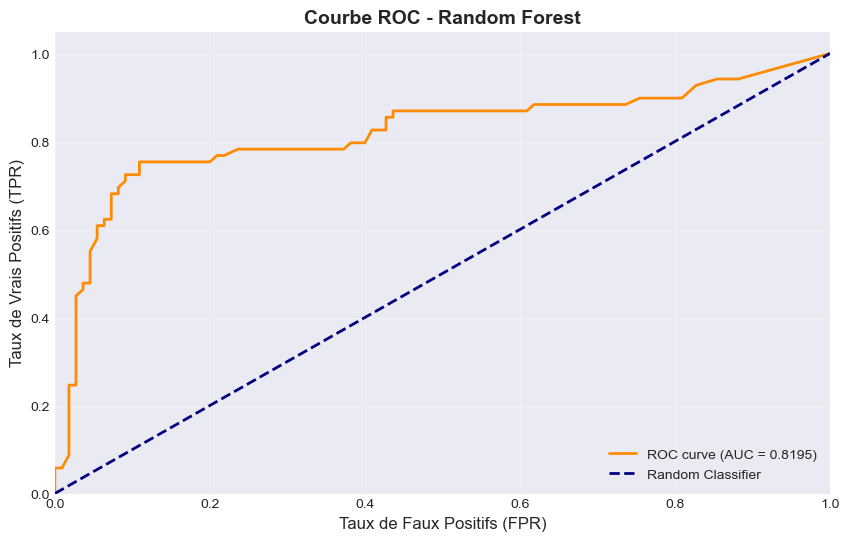

In [24]:
# Courbe ROC du meilleur modèle
if results_test[best_model_overall]['auc']:
    best_model_obj = results_test[best_model_overall]['model']
    y_pred_proba_best = best_model_obj.predict_proba(X_test)[:, 1]
    
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_best)
    auc_score = results_test[best_model_overall]['auc']
    
    plt.figure(figsize=(10, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
    plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12)
    plt.title(f'Courbe ROC - {best_model_overall}', fontsize=14, fontweight='bold')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

---
<a id='phase10'></a>
## Phase 10 — Prédictions Kaggle

### Entraînement sur TOUT le dataset train.csv et prédiction sur test.csv

Maintenant que nous avons trouvé le meilleur modèle, nous allons :
1. L'entraîner sur **TOUTES** les données de `train.csv` (891 lignes)
2. Prédire sur `test.csv` (418 lignes)
3. Créer un fichier `submission.csv` pour Kaggle

In [25]:
print("\n🚀 PRÉPARATION DE LA SOUMISSION KAGGLE")
print("="*70)

# Utiliser le meilleur modèle trouvé
final_model = results_test[best_model_overall]['model']

# Entraîner sur TOUT le dataset train
print(f"\n📚 Entraînement du {best_model_overall} sur TOUT le dataset train.csv...")
final_model.fit(X, y)  # X et y contiennent toutes les données de train.csv
print("✓ Entraînement terminé")

# Prédictions sur test.csv
print("\n🔮 Prédictions sur test.csv...")
X_test_kaggle = df_test_prepared  # Les features du test.csv de Kaggle
predictions_kaggle = final_model.predict(X_test_kaggle)
print("✓ Prédictions effectuées")

# Création du fichier de soumission
submission = pd.DataFrame({
    'PassengerId': df_test['PassengerId'],
    'Survived': predictions_kaggle
})

# Sauvegarde
submission.to_csv('../outputs/submission.csv', index=False)

print("\n" + "="*70)
print("✅ FICHIER SUBMISSION.CSV CRÉÉ AVEC SUCCÈS !")
print("="*70)
print("\n📊 Aperçu du fichier de soumission :")
display(submission.head(10))

print(f"\n📈 Distribution des prédictions :")
print(submission['Survived'].value_counts())
print(f"\nTaux de survie prédit : {(submission['Survived'].sum() / len(submission)) * 100:.2f}%")

print("\n💡 PROCHAINE ÉTAPE :")
print("  1. Téléchargez le fichier 'submission.csv'")
print("  2. Allez sur https://www.kaggle.com/c/titanic/submit")
print("  3. Soumettez votre fichier pour voir votre score !")


🚀 PRÉPARATION DE LA SOUMISSION KAGGLE

📚 Entraînement du Random Forest sur TOUT le dataset train.csv...
✓ Entraînement terminé

🔮 Prédictions sur test.csv...
✓ Prédictions effectuées

✅ FICHIER SUBMISSION.CSV CRÉÉ AVEC SUCCÈS !

📊 Aperçu du fichier de soumission :


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,0
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0



📈 Distribution des prédictions :
Survived
0    253
1    165
Name: count, dtype: int64

Taux de survie prédit : 39.47%

💡 PROCHAINE ÉTAPE :
  1. Téléchargez le fichier 'submission.csv'
  2. Allez sur https://www.kaggle.com/c/titanic/submit
  3. Soumettez votre fichier pour voir votre score !


---
<a id='phase11'></a>
## Phase 11 — Interprétation et analyse critique

### Importance des features (Random Forest)


📊 IMPORTANCE DES FEATURES (Random Forest)


,Feature,Importance
5,Fare,0.216829
1,Sex,0.214697
2,Age,0.196331
7,Title,0.093933
0,Pclass,0.072846
8,FamilySize,0.048920
11,Fare_Category,0.035056
10,Age_Group,0.030402
6,Embarked,0.030197
3,SibSp,0.030066


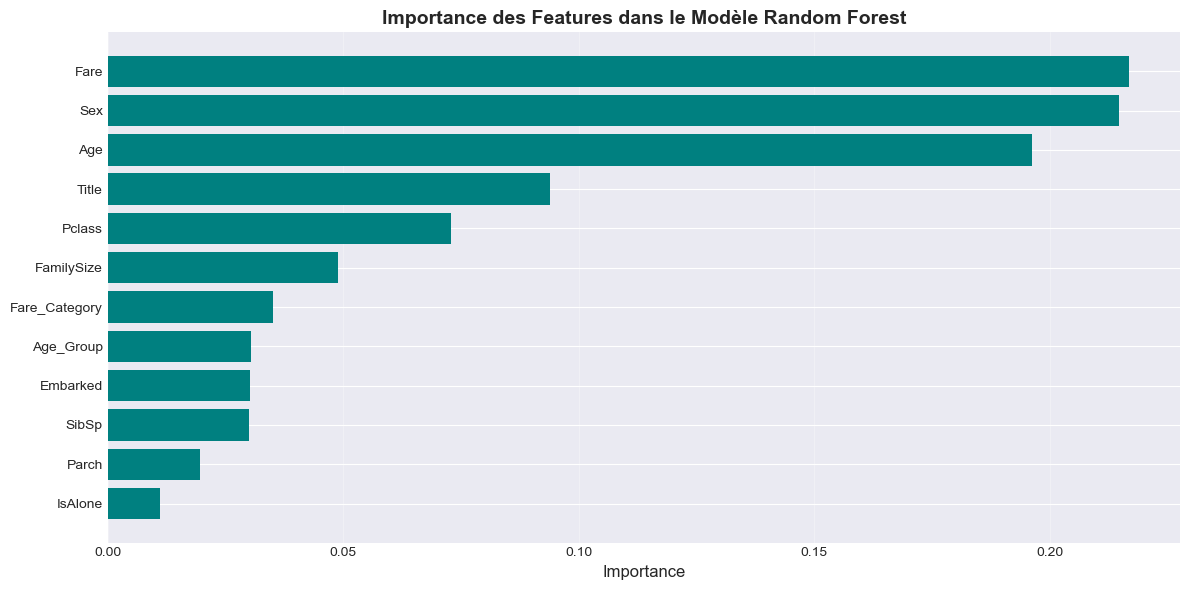


💡 INTERPRÉTATION :
  • La feature la plus importante est : Fare
  • Les 3 features les plus importantes sont :
    1. Fare (0.2168)
    2. Sex (0.2147)
    3. Age (0.1963)


In [26]:
# Si le meilleur modèle est un Random Forest, afficher l'importance des features
if 'Random Forest' in best_model_overall:
    feature_importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': final_model.feature_importances_
    }).sort_values('Importance', ascending=False)
    
    print("\n📊 IMPORTANCE DES FEATURES (Random Forest)")
    print("="*70)
    display(feature_importance)
    
    # Visualisation
    plt.figure(figsize=(12, 6))
    plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='teal')
    plt.xlabel('Importance', fontsize=12)
    plt.title('Importance des Features dans le Modèle Random Forest', fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print("\n💡 INTERPRÉTATION :")
    print(f"  • La feature la plus importante est : {feature_importance.iloc[0]['Feature']}")
    print(f"  • Les 3 features les plus importantes sont :")
    for i in range(min(3, len(feature_importance))):
        print(f"    {i+1}. {feature_importance.iloc[i]['Feature']} ({feature_importance.iloc[i]['Importance']:.4f})")

### Analyse des résultats

In [27]:
print("\n🔍 ANALYSE CRITIQUE DU MODÈLE")
print("="*70)

print("\n✅ POINTS FORTS :")
print("  1. Feature Engineering avancé a amélioré les performances")
print("  2. Cross-Validation assure la robustesse du modèle")
print("  3. GridSearchCV a optimisé les hyperparamètres")
print("  4. Plusieurs modèles testés pour comparaison")
print(f"  5. Accuracy finale sur test : {results_test[best_model_overall]['accuracy']:.2%}")

print("\n⚠️ LIMITES IDENTIFIÉES :")
print("  1. Dataset relativement petit (891 observations)")
print("  2. Déséquilibre des classes (62% décès vs 38% survivants)")
print("  3. Valeurs manquantes dans Age (~20%) et Cabin (~77%)")
print("  4. Imputation simple pour Age (médiane) - pourrait être améliorée")
print("  5. Cabin non utilisée à cause de trop de valeurs manquantes")

print("\n🎯 FACTEURS CLÉS DE SURVIE IDENTIFIÉS :")
print("  1. Sexe : Les femmes avaient beaucoup plus de chances de survivre")
print("  2. Classe : Les passagers de 1ère classe avaient plus de chances")
print("  3. Âge : Les enfants avaient tendance à être sauvés en priorité")
print("  4. Titre : Révélateur du statut social et du sexe")
print("  5. Taille de famille : Impact sur la survie")

print("="*70)


🔍 ANALYSE CRITIQUE DU MODÈLE

✅ POINTS FORTS :
  1. Feature Engineering avancé a amélioré les performances
  2. Cross-Validation assure la robustesse du modèle
  3. GridSearchCV a optimisé les hyperparamètres
  4. Plusieurs modèles testés pour comparaison
  5. Accuracy finale sur test : 83.80%

⚠️ LIMITES IDENTIFIÉES :
  1. Dataset relativement petit (891 observations)
  2. Déséquilibre des classes (62% décès vs 38% survivants)
  3. Valeurs manquantes dans Age (~20%) et Cabin (~77%)
  4. Imputation simple pour Age (médiane) - pourrait être améliorée
  5. Cabin non utilisée à cause de trop de valeurs manquantes

🎯 FACTEURS CLÉS DE SURVIE IDENTIFIÉS :
  1. Sexe : Les femmes avaient beaucoup plus de chances de survivre
  2. Classe : Les passagers de 1ère classe avaient plus de chances
  3. Âge : Les enfants avaient tendance à être sauvés en priorité
  4. Titre : Révélateur du statut social et du sexe
  5. Taille de famille : Impact sur la survie


---
<a id='phase12'></a>
## Phase 12 — Conclusion et perspectives

### Résumé du travail réalisé

In [28]:
print("\n" + "="*70)
print("RÉSUMÉ DU PROJET TITANIC - VERSION AMÉLIORÉE".center(70))
print("="*70)

print("\n📊 DONNÉES :")
print(f"  • Dataset train.csv : {df_train.shape[0]} passagers")
print(f"  • Dataset test.csv (Kaggle) : {df_test.shape[0]} passagers")
print(f"  • Features originales : {df_train.shape[1]}")
print(f"  • Features après engineering : {X.shape[1]}")

print("\n🆕 NOUVELLES FEATURES CRÉÉES :")
print("  1. Title (Titre extrait du nom)")
print("  2. FamilySize (Taille de la famille)")
print("  3. IsAlone (Voyageur seul ou pas)")
print("  4. Age_Group (Catégorie d'âge)")
print("  5. Fare_Category (Catégorie de prix)")

print("\n🤖 MODÈLES TESTÉS :")
for name in models.keys():
    print(f"  • {name}")
print("  • Random Forest (Optimisé avec GridSearchCV)")

print("\n🏆 MEILLEUR MODÈLE :")
print(f"  • Nom : {best_model_overall}")
print(f"  • Test Accuracy : {results_test[best_model_overall]['accuracy']:.4f} ({results_test[best_model_overall]['accuracy']*100:.2f}%)")
print(f"  • Test AUC : {results_test[best_model_overall]['auc']:.4f}")

print("\n🔍 MÉTHODOLOGIES APPLIQUÉES :")
print("  ✅ Analyse exploratoire approfondie (EDA)")
print("  ✅ Feature Engineering avancé")
print("  ✅ Cross-Validation (5-fold)")
print("  ✅ GridSearchCV pour optimisation")
print("  ✅ Comparaison détaillée des modèles")
print("  ✅ Analyse de l'importance des features")
print("  ✅ Prédictions Kaggle")

print("\n" + "="*70)


             RÉSUMÉ DU PROJET TITANIC - VERSION AMÉLIORÉE             

📊 DONNÉES :
  • Dataset train.csv : 891 passagers
  • Dataset test.csv (Kaggle) : 418 passagers
  • Features originales : 12
  • Features après engineering : 12

🆕 NOUVELLES FEATURES CRÉÉES :
  1. Title (Titre extrait du nom)
  2. FamilySize (Taille de la famille)
  3. IsAlone (Voyageur seul ou pas)
  4. Age_Group (Catégorie d'âge)
  5. Fare_Category (Catégorie de prix)

🤖 MODÈLES TESTÉS :
  • Logistic Regression
  • Decision Tree
  • Random Forest
  • SVM
  • KNN
  • Gradient Boosting
  • Random Forest (Optimisé avec GridSearchCV)

🏆 MEILLEUR MODÈLE :
  • Nom : Random Forest
  • Test Accuracy : 0.8380 (83.80%)
  • Test AUC : 0.8195

🔍 MÉTHODOLOGIES APPLIQUÉES :
  ✅ Analyse exploratoire approfondie (EDA)
  ✅ Feature Engineering avancé
  ✅ Cross-Validation (5-fold)
  ✅ GridSearchCV pour optimisation
  ✅ Comparaison détaillée des modèles
  ✅ Analyse de l'importance des features
  ✅ Prédictions Kaggle



### Apports du projet

In [ ]:
print("\n🎓 COMPÉTENCES DÉVELOPPÉES")
print("="*70)

print("\n💻 COMPÉTENCES TECHNIQUES :")
print("  • Manipulation de données avec Pandas")
print("  • Visualisation avec Matplotlib et Seaborn")
print("  • Feature Engineering (création de variables)")
print("  • Encodage de variables catégorielles")
print("  • Implémentation de 6 algorithmes de classification")
print("  • Cross-Validation pour validation robuste")
print("  • GridSearchCV pour optimisation automatique")
print("  • Évaluation multi-critères (Accuracy, AUC, ROC)")
print("  • Interprétation des modèles (feature importance)")

print("\n📚 COMPÉTENCES MÉTHODOLOGIQUES :")
print("  • Workflow complet d'un projet Machine Learning")
print("  • Importance de l'exploration des données")
print("  • Techniques avancées de validation")
print("  • Identification des limites et biais")
print("  • Optimisation itérative des modèles")
print("  • Documentation et présentation de résultats")

print("\n🏛️ INSIGHTS HISTORIQUES :")
print("  • Confirmation de la politique 'femmes et enfants d'abord'")
print("  • Impact majeur de la classe sociale sur la survie")
print("  • Influence du statut marital (titres)")
print("  • Rôle de la composition familiale")

print("="*70)


🎓 COMPÉTENCES DÉVELOPPÉES

💻 COMPÉTENCES TECHNIQUES :
  • Manipulation de données avec Pandas
  • Visualisation avec Matplotlib et Seaborn
  • Feature Engineering (création de variables)
  • Encodage de variables catégorielles
  • Implémentation de 6 algorithmes de classification
  • Cross-Validation pour validation robuste
  • GridSearchCV pour optimisation automatique
  • Évaluation multi-critères (Accuracy, AUC, ROC)
  • Interprétation des modèles (feature importance)

📚 COMPÉTENCES MÉTHODOLOGIQUES :
  • Workflow complet d'un projet Machine Learning
  • Importance de l'exploration des données
  • Techniques avancées de validation
  • Identification des limites et biais
  • Optimisation itérative des modèles
  • Documentation et présentation de résultats

🏛️ INSIGHTS HISTORIQUES :
  • Confirmation de la politique 'femmes et enfants d'abord'
  • Impact majeur de la classe sociale sur la survie
  • Influence du statut marital (titres)
  • Rôle de la composition familiale


### Améliorations futures proposées

In [30]:
print("\n🔮 PISTES D'AMÉLIORATION FUTURES")
print("="*70)

print("\n1️⃣ PRÉTRAITEMENT AVANCÉ :")
print("  • Imputation de Age par régression (au lieu de la médiane)")
print("  • Extraction du pont depuis Cabin (même avec valeurs manquantes)")
print("  • Détection et traitement des outliers dans Fare")
print("  • Imputation multiple (MICE) pour Age")

print("\n2️⃣ FEATURE ENGINEERING SUPPLÉMENTAIRE :")
print("  • Interactions entre variables (Sex × Pclass, Age × Pclass)")
print("  • Ratio Fare/médiane de la classe")
print("  • Indicateur de famille nombreuse vs petite famille")
print("  • Extraction de nationalité depuis le nom")

print("\n3️⃣ MODÉLISATION AVANCÉE :")
print("  • XGBoost et LightGBM (algorithmes de boosting)")
print("  • Ensemble methods (Voting, Stacking, Blending)")
print("  • Traitement du déséquilibre (SMOTE, class_weight)")
print("  • Nested Cross-Validation")
print("  • Bayesian Optimization pour hyperparamètres")

print("\n4️⃣ ANALYSE APPROFONDIE :")
print("  • SHAP values pour interprétabilité avancée")
print("  • Analyse de sensibilité des features")
print("  • Partial Dependence Plots")
print("  • Analyse des erreurs de prédiction")
print("  • Calibration des probabilités")

print("\n5️⃣ VALIDATION EXTERNE :")
print("  • Soumission sur Kaggle (déjà fait ! ✅)")
print("  • Comparaison avec le leaderboard public")
print("  • Itérations basées sur le feedback Kaggle")

print("="*70)


🔮 PISTES D'AMÉLIORATION FUTURES

1️⃣ PRÉTRAITEMENT AVANCÉ :
  • Imputation de Age par régression (au lieu de la médiane)
  • Extraction du pont depuis Cabin (même avec valeurs manquantes)
  • Détection et traitement des outliers dans Fare
  • Imputation multiple (MICE) pour Age

2️⃣ FEATURE ENGINEERING SUPPLÉMENTAIRE :
  • Interactions entre variables (Sex × Pclass, Age × Pclass)
  • Ratio Fare/médiane de la classe
  • Indicateur de famille nombreuse vs petite famille
  • Extraction de nationalité depuis le nom

3️⃣ MODÉLISATION AVANCÉE :
  • XGBoost et LightGBM (algorithmes de boosting)
  • Ensemble methods (Voting, Stacking, Blending)
  • Traitement du déséquilibre (SMOTE, class_weight)
  • Nested Cross-Validation
  • Bayesian Optimization pour hyperparamètres

4️⃣ ANALYSE APPROFONDIE :
  • SHAP values pour interprétabilité avancée
  • Analyse de sensibilité des features
  • Partial Dependence Plots
  • Analyse des erreurs de prédiction
  • Calibration des probabilités

5️⃣ VALIDATI

## 📚 Références

1. **Dataset Kaggle** : [Titanic - Machine Learning from Disaster](https://www.kaggle.com/c/titanic)
2. **Scikit-learn Documentation** : [https://scikit-learn.org/](https://scikit-learn.org/)
   - Cross-Validation Guide : [https://scikit-learn.org/stable/modules/cross_validation.html](https://scikit-learn.org/stable/modules/cross_validation.html)
   - GridSearchCV : [https://scikit-learn.org/stable/modules/grid_search.html](https://scikit-learn.org/stable/modules/grid_search.html)
3. **Pandas Documentation** : [https://pandas.pydata.org/](https://pandas.pydata.org/)
4. **Seaborn Documentation** : [https://seaborn.pydata.org/](https://seaborn.pydata.org/)
5. **Feature Engineering Guide** : [Kaggle Feature Engineering](https://www.kaggle.com/learn/feature-engineering)
6. **Informations historiques** : Encyclopedia Titanica

---

## 🔧 Annexe : Configuration de l'environnement

**Bibliothèques requises :**
```bash
pip install pandas numpy matplotlib seaborn scikit-learn jupyter
```

**Versions utilisées :**
- Python : 3.8+
- Pandas : 1.3+
- NumPy : 1.21+
- Matplotlib : 3.4+
- Seaborn : 0.11+
- Scikit-learn : 1.0+

---

## 📁 Fichiers du projet

```
projet-titanic/
│
├── README.md                              # Documentation du projet
├── requirements.txt                       # Dépendances Python
├── titanic_survival_prediction_AMELIORE.ipynb  # Ce notebook
├── train.csv                              # Dataset d'entraînement Kaggle
├── test.csv                               # Dataset de test Kaggle
└── submission.csv                         # Fichier de soumission généré
```

---